# 03. Grover's search algorithm
Searches $N=2^n$ items for one marked bitstring using about $\frac{\pi}{4}\sqrt{N}$ iterations of *oracle + diffuser*, instead of about $N/2$ classical guesses.

In [1]:
import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

def create_oracle(n, target):
    """Flips the phase of the basis state |target>."""
    qc = QuantumCircuit(n, name="Oracle")
    rev = target[::-1]                       # Qiskit is little-endian
    for i, bit in enumerate(rev):
        if bit == '0': qc.x(i)
    qc.h(n-1); qc.mcx(list(range(n-1)), n-1); qc.h(n-1)   # multi-controlled Z
    for i, bit in enumerate(rev):
        if bit == '0': qc.x(i)
    return qc

def diffuser(n):
    """Inversion about the mean."""
    qc = QuantumCircuit(n, name="Diffuser")
    qc.h(range(n)); qc.x(range(n))
    qc.h(n-1); qc.mcx(list(range(n-1)), n-1); qc.h(n-1)
    qc.x(range(n)); qc.h(range(n))
    return qc

In [2]:
target = "1010"
n = len(target)
iterations = int(np.floor(np.pi/4 * np.sqrt(2**n)))
print("iterations:", iterations)

grover = QuantumCircuit(n, n)
grover.h(range(n)); grover.barrier()
for _ in range(iterations):
    grover.compose(create_oracle(n, target), inplace=True); grover.barrier()
    grover.compose(diffuser(n), inplace=True); grover.barrier()
grover.measure(range(n), range(n))

sim = AerSimulator()
counts = sim.run(transpile(grover, sim), shots=1024).result().get_counts()
print("Target:", target, "| most frequent:", max(counts, key=counts.get), "| shots on target:", counts.get(target,0), "/ 1024")

iterations: 3
Target: 1010 | most frequent: 1010 | shots on target: 983 / 1024


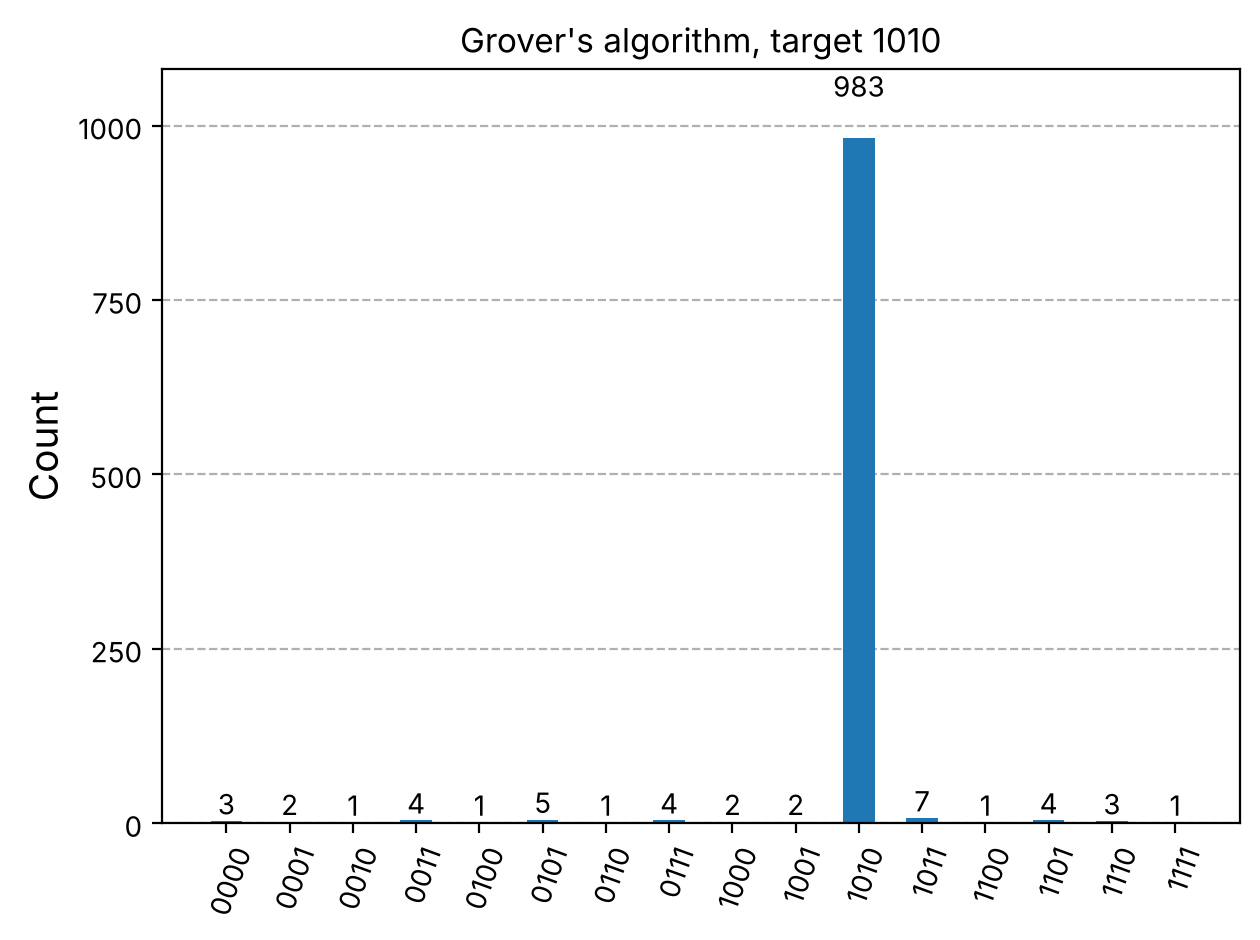

In [3]:
plot_histogram(counts, title="Grover's algorithm, target 1010")